In [82]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import imageio
import numpy as np

Graph named "Zachary's Karate Club" with 34 nodes and 78 edges


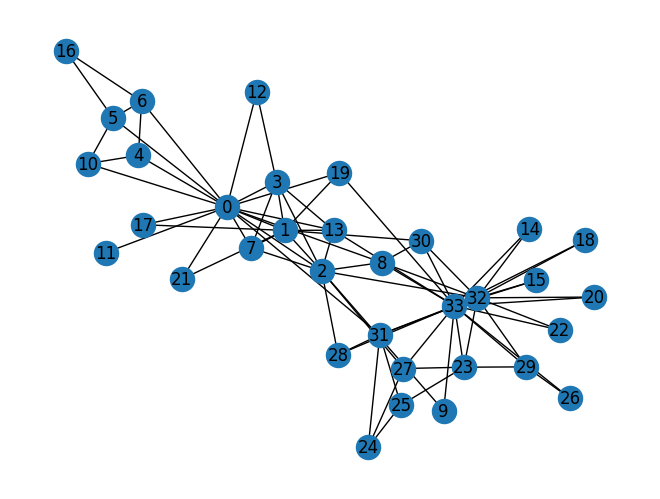

[(0, {'club': 'Mr. Hi'}), (1, {'club': 'Mr. Hi'}), (2, {'club': 'Mr. Hi'}), (3, {'club': 'Mr. Hi'}), (4, {'club': 'Mr. Hi'}), (5, {'club': 'Mr. Hi'}), (6, {'club': 'Mr. Hi'}), (7, {'club': 'Mr. Hi'}), (8, {'club': 'Mr. Hi'}), (9, {'club': 'Officer'}), (10, {'club': 'Mr. Hi'}), (11, {'club': 'Mr. Hi'}), (12, {'club': 'Mr. Hi'}), (13, {'club': 'Mr. Hi'}), (14, {'club': 'Officer'}), (15, {'club': 'Officer'}), (16, {'club': 'Mr. Hi'}), (17, {'club': 'Mr. Hi'}), (18, {'club': 'Officer'}), (19, {'club': 'Mr. Hi'}), (20, {'club': 'Officer'}), (21, {'club': 'Mr. Hi'}), (22, {'club': 'Officer'}), (23, {'club': 'Officer'}), (24, {'club': 'Officer'}), (25, {'club': 'Officer'}), (26, {'club': 'Officer'}), (27, {'club': 'Officer'}), (28, {'club': 'Officer'}), (29, {'club': 'Officer'}), (30, {'club': 'Officer'}), (31, {'club': 'Officer'}), (32, {'club': 'Officer'}), (33, {'club': 'Officer'})]


In [83]:
G = nx.karate_club_graph()
print(G)

nx.draw(G, with_labels=True)
plt.show()
print(G.nodes(data=True))

In [84]:
# add state to each node, 1 for mr Hi 0 for John A, 0.5 to everyone else
for node in G.nodes:
    match node:
        case 0:  # Mr. Hi
            G.nodes[node]["state"] = 1.0
        case 33:  # John A
            G.nodes[node]["state"] = 0.0
        case _:  # Everyone else
            G.nodes[node]["state"] = 0.5

print(G.nodes(data=True))

# add weights to all edges
for edge in G.edges:
    G.edges[edge]['weight'] = 0.5

print(G.edges(data=True))

[(0, {'club': 'Mr. Hi', 'state': 1.0}), (1, {'club': 'Mr. Hi', 'state': 0.5}), (2, {'club': 'Mr. Hi', 'state': 0.5}), (3, {'club': 'Mr. Hi', 'state': 0.5}), (4, {'club': 'Mr. Hi', 'state': 0.5}), (5, {'club': 'Mr. Hi', 'state': 0.5}), (6, {'club': 'Mr. Hi', 'state': 0.5}), (7, {'club': 'Mr. Hi', 'state': 0.5}), (8, {'club': 'Mr. Hi', 'state': 0.5}), (9, {'club': 'Officer', 'state': 0.5}), (10, {'club': 'Mr. Hi', 'state': 0.5}), (11, {'club': 'Mr. Hi', 'state': 0.5}), (12, {'club': 'Mr. Hi', 'state': 0.5}), (13, {'club': 'Mr. Hi', 'state': 0.5}), (14, {'club': 'Officer', 'state': 0.5}), (15, {'club': 'Officer', 'state': 0.5}), (16, {'club': 'Mr. Hi', 'state': 0.5}), (17, {'club': 'Mr. Hi', 'state': 0.5}), (18, {'club': 'Officer', 'state': 0.5}), (19, {'club': 'Mr. Hi', 'state': 0.5}), (20, {'club': 'Officer', 'state': 0.5}), (21, {'club': 'Mr. Hi', 'state': 0.5}), (22, {'club': 'Officer', 'state': 0.5}), (23, {'club': 'Officer', 'state': 0.5}), (24, {'club': 'Officer', 'state': 0.5}), (

In [85]:
def node_evolution(node, G, D, dt):
    if node == 0: # Mr. Hi
        return 1
    elif node == 33: # John A.
        return 0
    
    total_sum = 0.0

    current_state = G.nodes[node]['state']

    for neighbor in G.neighbors(node):
        neighbor_state = G.nodes[neighbor]['state']
        weight = G[node][neighbor].get('weight')

        total_sum += (neighbor_state - current_state) * weight

    return current_state + D * total_sum * dt

def node_state_calculation(G, D, dt):

    next_states = {}
    for node in G.nodes:
        next_states[node] = node_evolution(node, G, D, dt)

    return next_states

def edge_evolution(edge, G, beta, dt):
    node1, node2 = edge

    state1 = G.nodes[node1]['state']
    state2 = G.nodes[node2]['state']

    edge_weight = G[node1][node2].get('weight')

    diff = abs(state1 - state2)
    f = (diff - 0.25) ** 3
    
    return edge_weight + beta * (1 - edge_weight) * f * dt

def edge_state_calculation(G, beta, dt):
    next_weights = {}

    for edge in G.edges:
        next_weights[edge] = edge_evolution(edge, G, beta, dt)

    return next_weights

import matplotlib.cm as cm
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

def plot_network_frame(g):
    """Draws the network state and returns the frame as a NumPy RGB array."""
    fig, ax = plt.subplots(figsize=(8, 8))

    if not hasattr(g, "pos"):
        g.pos = nx.spring_layout(g, k=0.3, seed=42)

    node_colors = [g.nodes[i]["state"] for i in g.nodes]
    
    # VISUAL UPGRADE: Map edge weights directly to Alpha (Opacity).
    # Format: (R, G, B, Alpha). We use Black (0, 0, 0) and set Alpha = weight.
    # The max/min ensures the alpha stays strictly between 0 and 1.
    edge_colors_rgba = [
        (0.0, 0.0, 0.0, max(0.0, min(1.0, g.edges[i, j]["weight"]))) 
        for i, j in g.edges
    ]

    nx.draw(
        g,
        pos=g.pos,
        with_labels=True,
        ax=ax,
        # Node styling
        node_color=node_colors,
        cmap=cm.coolwarm,  # Dark Blue (0) -> Gray (0.5) -> Dark Red (1)
        vmin=0,
        vmax=1,
        node_size=600,     
        font_color="white",
        font_weight="bold",
        # Edge styling
        edge_color=edge_colors_rgba, # Pass the explicit RGBA list
        width=2.5,                   # Locked width so opacity is highly visible
    )

    fig.canvas.draw()
    rgba_buffer = fig.canvas.buffer_rgba()
    frame = np.asarray(rgba_buffer)
    frame = frame[..., :3]

    plt.close(fig) 

    return frame

In [86]:
TIME_STEPS = 1000
D = 5
dt = 0.01
beta = 10

frames = []
frames.append(plot_network_frame(G))

for i in range(TIME_STEPS):
    # calculate the new node states
    next_states = node_state_calculation(G, D, dt)

    # calculate the new weights for edges
    next_weight = edge_state_calculation(G, beta, dt)

    # assign the new values
    for node, new_state in next_states.items():
        G.nodes[node]['state'] = max(0.0, min(1.0, new_state))


    for edge, new_weight in next_weight.items():
        u, v = edge
        G[u][v]['weight'] = max(0.0, min(1.0, new_weight))

    if i % 10 == 0:
        frames.append(plot_network_frame(G))
    
imageio.mimsave('the_beef.gif', frames, fps=10, loop=0)
